Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [1]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy

import cvxpy as cp
import gurobipy as gp

from scipy.optimize import least_squares

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel as Model
from Components.Model import IrrigationSchedulingCost as CostModel
from Components.Controllers import TimeVaryingCost_LQRc_RHG as Controller
from Components.Solver import fbrs

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [3]:
parameter_file = "Components/Setup/model_parameters_myopic.json"
crop_repartition = np.array([[0.5, 0.8, 0.3], [0., 0.2, 0.3], [0.4, 0., 0.3], [0., 0., 0.4]])

In [4]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = Model(parameter_file, boundary_condition="Constant Head")
cost_model = CostModel(parameter_file, model, crop_repartition)

In [5]:
n_well = model.well_to_agent.shape[0]

In [6]:
# Define base pumping commands
T = 100
base_command = np.split(np.kron(np.eye(n_well), -np.ones((1,T))), T*np.linspace(1,n_well-1,n_well-1, dtype=int), axis=1)
# Other pumping parameters
max_intensity = 1000
n_steps_intensity = 10
intensity_step = max_intensity/n_steps_intensity

In [7]:
# Compute heads and costs for different commands at different wells
head = np.array([[np.hstack((system.get_heads_at_wells()[:,np.newaxis], np.zeros((n_well, T))))] * n_steps_intensity] * n_well)
cost = np.array([[np.zeros((model.n_agent, T))] * n_steps_intensity] * n_well)
for ii in range(n_well):
    for step in trange(n_steps_intensity):
        system.state = system.initial_state.copy()
        intensity = (step+1)*intensity_step
        for k in range(T):
            system.apply_command(intensity*base_command[ii][:, [k]])
            head[ii, step, :, k+1] = system.get_heads_at_wells()

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [01:17<00:00,  7.74s/it]


In [8]:
# Compute expected heads for those commands
B = sp.hstack(model.B_v)
system.state = system.initial_state.copy()
model_head = np.array([[np.hstack((model.translate_state(system.get_state()[0,:,:]), np.zeros((model.nx, T))))] * n_steps_intensity] * n_well)
model_cost = np.array([[np.zeros((model.n_agent, T))] * n_steps_intensity] * n_well)
for ii in range(n_well):
    inputs = np.kron(sp.vstack(model.well_to_command_v) @ base_command[ii], np.array([[1] + [0]*(model.n_crops-1)]).T)
    for step in trange(n_steps_intensity):
        intensity = (step+1)*intensity_step
        for k in range(T):
            input = intensity*inputs[:,[k]]
            model.state = model_head[ii, step, :, [k]].T
            model_head[ii, step, :, k+1] = (model.A @ model_head[ii, step, :, [k]].T + B @ input + model.C).flatten()

100%|██████████| 10/10 [00:00<00:00, 212.85it/s]


#### Plot head gaps for the different setups

In [9]:
well_pos = np.nonzero(model.well_to_cell.T)[1]

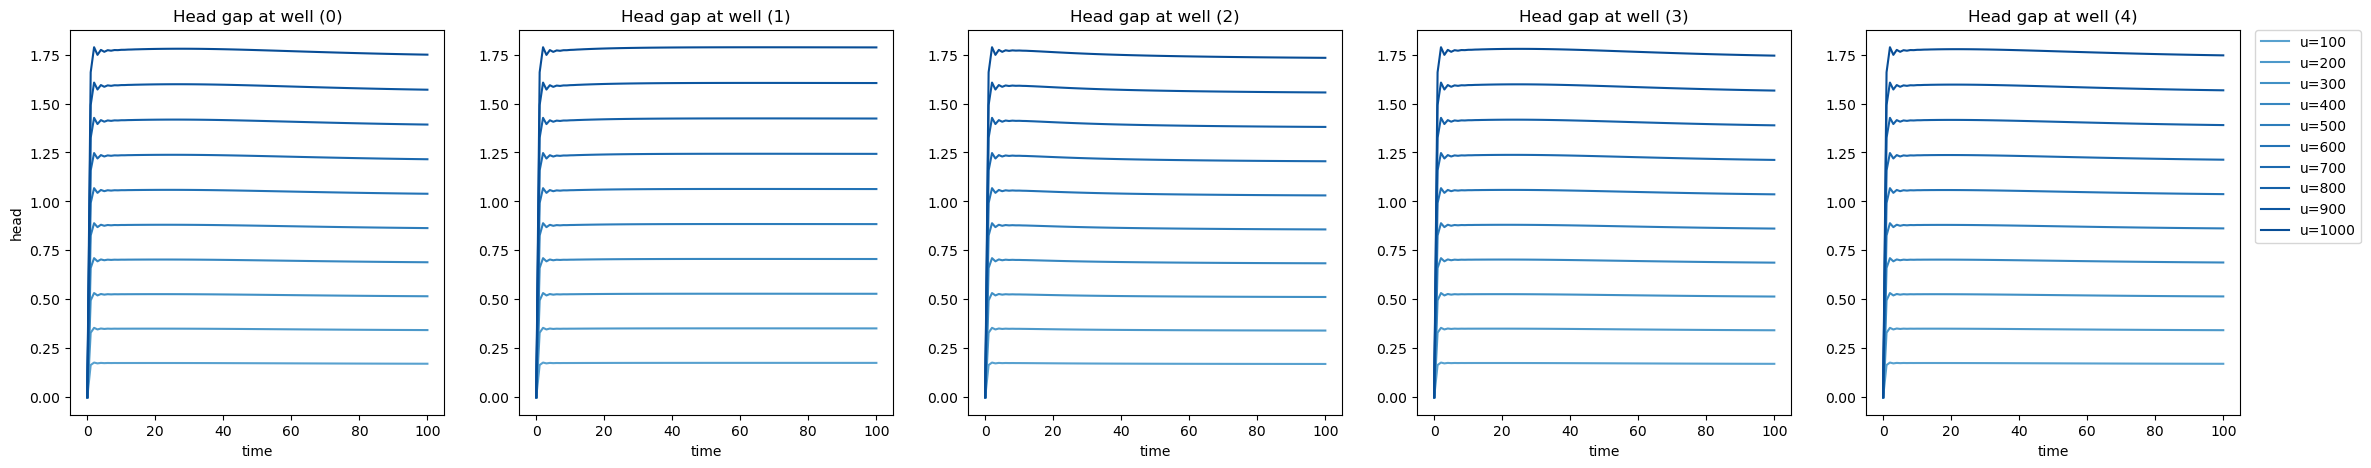

In [10]:
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    for n_i in range(n_steps_intensity):
        # ax_h.plot(response[ii][n_i][well_pos[ii], :], "b-")
        # ax_h.plot(model_response[ii][n_i][well_pos[ii], :], "b--")
        ax_h.plot(model_head[ii, n_i, well_pos[ii], :] - head[ii, n_i, ii, :], color=plt.get_cmap('Blues')((15+n_i)/(n_steps_intensity+17)), label=f"u={int((n_i+1)*intensity_step)}")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Correction on the heads

## Using random inputs as training data

In [14]:
n_sample = 100
train_command = [(np.random.randint(-3000,0, (1,5))*np.ones((T, 5))).T for _ in range(n_sample)]

In [15]:
model.translate_state(system.get_state()[0,:,:]).flatten().shape

(100,)

In [16]:
# Compute heads and costs for different commands at different wells
head_rd = np.array([np.hstack((system.get_heads_at_wells()[:,np.newaxis], np.zeros((n_well, T))))] * n_sample)
cost_rd = np.array([np.zeros((model.n_agent, T))] * n_sample)
for step in trange(n_sample):
    system.state = system.initial_state.copy()
    for k in range(T):
        system.apply_command(train_command[step][:,[k]])
        head_rd[step, :, k+1] = system.get_heads_at_wells()
        cost_rd[step, :, k] = system.compute_cost(train_command[step][:,[k]]).flatten()

100%|██████████| 100/100 [18:01<00:00, 10.82s/it]


In [17]:
# Compute expected heads for those commands
B = sp.hstack(model.B_v)
system.state = system.initial_state.copy()
model_head_rd = np.array([np.hstack((model.translate_state(system.get_state()[0,:,:]), np.zeros((model.nx, T))))] * n_sample)
model_cost_rd = np.array([np.zeros((model.n_agent, T))] * n_sample)
for step in trange(n_sample):
    for k in range(T):
        input = np.kron(sp.vstack(model.well_to_command_v) @ train_command[step][:,[k]], np.array([[1] + [0]*(model.n_crops-1)]).T)
        model.state = model_head_rd[step, :, [k]].T
        model_head_rd[step, :, k+1] = (model.A @ model_head_rd[step, :, [k]].T + B @ input + model.C).flatten()

100%|██████████| 100/100 [00:02<00:00, 37.32it/s]


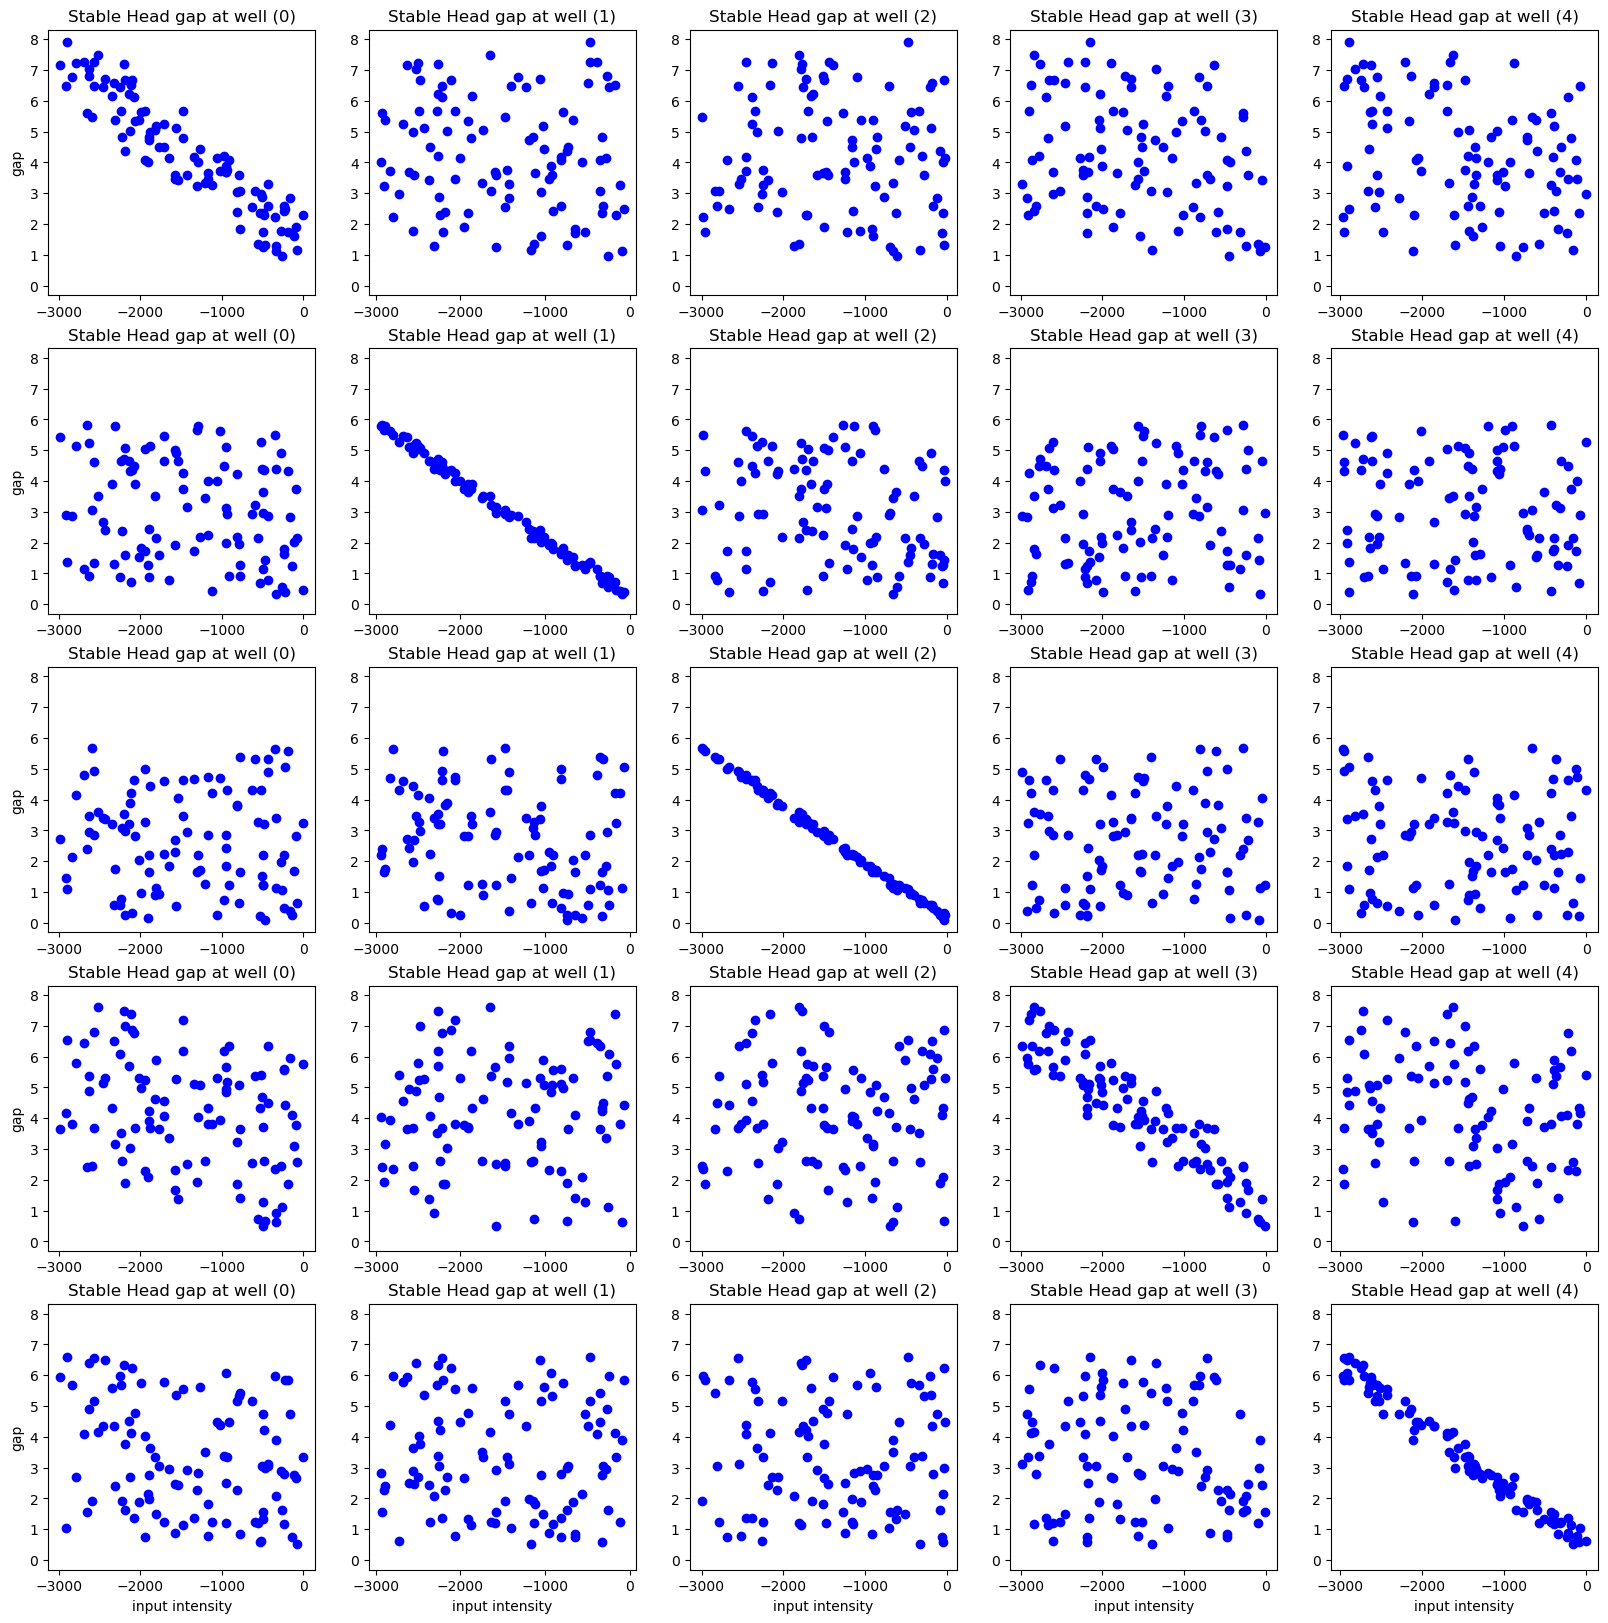

In [18]:
fig_h = plt.figure(figsize=(20,20))
ax_h = None
for ii in range(n_well):
    for jj in range(n_well):
        ax_h = fig_h.add_subplot(5, 5, 5*jj+ii+1, sharey=ax_h)
        ttl = f"Stable Head gap at well ({ii})"
        ax_h.set_title(ttl)
        if jj == n_well-1:
            ax_h.set_xlabel("input intensity")
        if ii == 0:
            ax_h.set_ylabel("gap")
        ax_h.scatter([train_command[_][ii,0] for _ in range(n_sample)], model_head_rd[:, well_pos[jj], -1] - head_rd[:, jj, -1], color="blue", label="data")

The only real corelation seems to be in it's own well.

Fit linear function between pumping at well and error term in the same well.

In [19]:
pumping_rates = np.array([[train_command[_][ii,0] for _ in range(n_sample)] for ii in range(n_well)])
error = np.array([model_head_rd[:, well_pos[ii], -1] - head_rd[:, ii, -1] for ii in range(n_well)])

In [20]:
res = least_squares(lambda x : (x*pumping_rates.flatten() - error.flatten()), x0 = 0)
cx_u = res.x

In [21]:
cx_u

array([-0.00227182])

In [22]:
res = least_squares(lambda x : ((pumping_rates.T*x).T - error).flatten(), x0 = [0,0,0,0,0])
cx_u_w = res.x
cx_u_w

array([-0.00272117, -0.00200885, -0.00191229, -0.00249413, -0.00220109])

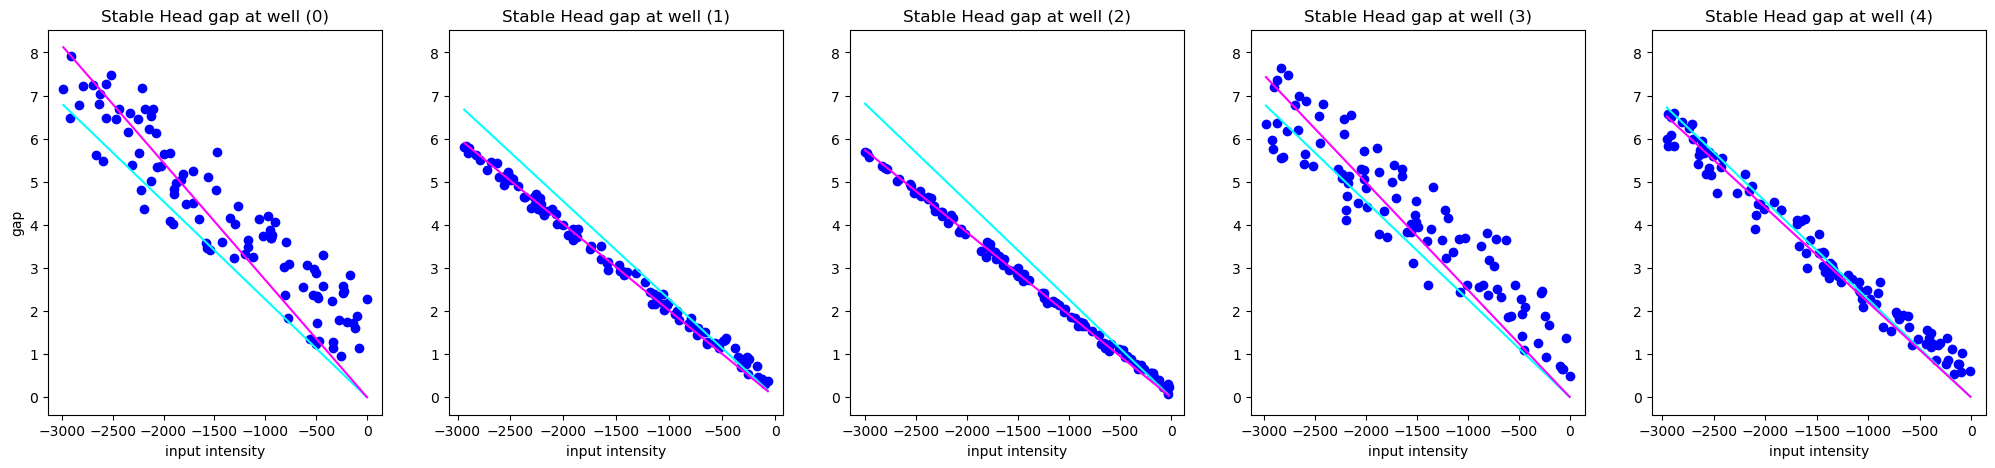

In [23]:
fig_h = plt.figure(figsize=(25,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Stable Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("input intensity")
    if ii == 0:
        ax_h.set_ylabel("gap")
    ax_h.scatter([train_command[_][ii,0] for _ in range(n_sample)], model_head_rd[:, well_pos[ii], -1] - head_rd[:, ii, -1], color="blue", label="data")
    arg_sort = pumping_rates[ii,:].argsort()
    ax_h.plot(pumping_rates[ii,arg_sort], cx_u * pumping_rates[ii,arg_sort], color="cyan")
    ax_h.plot(pumping_rates[ii,arg_sort], (pumping_rates.T * cx_u_w).T[ii,arg_sort], color="magenta")

# Smaller cells

In [24]:
parameter_file = "Components/Setup/test_scenarios_parameters.json"
crop_repartition = np.array([[0.5, 0.8, 0.3], [0., 0.2, 0.3], [0.4, 0., 0.3], [0., 0., 0.4]])

In [25]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = Model(parameter_file, boundary_condition="Constant Head")
cost_model = CostModel(parameter_file, model, crop_repartition)

In [26]:
n_well = model.well_to_agent.shape[0]

In [27]:
# Define base pumping commands
T = 100
base_command = np.split(np.kron(np.eye(n_well), -np.ones((1,T))), T*np.linspace(1,n_well-1,n_well-1, dtype=int), axis=1)
# Other pumping parameters
max_intensity = 1000
n_steps_intensity = 10
intensity_step = max_intensity/n_steps_intensity

In [28]:
# Compute heads and costs for different commands at different wells
head = np.array([[np.hstack((system.get_heads_at_wells()[:,np.newaxis], np.zeros((n_well, T))))] * n_steps_intensity] * n_well)
cost = np.array([[np.zeros((model.n_agent, T))] * n_steps_intensity] * n_well)
for ii in range(n_well):
    for step in trange(n_steps_intensity):
        system.state = system.initial_state.copy()
        intensity = (step+1)*intensity_step
        for k in range(T):
            system.apply_command(intensity*base_command[ii][:, [k]])
            head[ii, step, :, k+1] = system.get_heads_at_wells()

100%|██████████| 10/10 [01:48<00:00, 10.84s/it]


In [29]:
# Compute expected heads for those commands
B = sp.hstack(model.B_v)
system.state = system.initial_state.copy()
model_head = np.array([[np.hstack((model.translate_state(system.get_state()[0,:,:]), np.zeros((model.nx, T))))] * n_steps_intensity] * n_well)
model_cost = np.array([[np.zeros((model.n_agent, T))] * n_steps_intensity] * n_well)
for ii in range(n_well):
    inputs = np.kron(sp.vstack(model.well_to_command_v) @ base_command[ii], np.array([[1] + [0]*(model.n_crops-1)]).T)
    for step in trange(n_steps_intensity):
        intensity = (step+1)*intensity_step
        for k in range(T):
            input = intensity*inputs[:,[k]]
            model.state = model_head[ii, step, :, [k]].T
            model_head[ii, step, :, k+1] = (model.A @ model_head[ii, step, :, [k]].T + B @ input + model.C).flatten()

100%|██████████| 10/10 [00:00<00:00, 43.60it/s]


#### Plot head gaps for the different setups

In [31]:
well_pos = np.nonzero(model.well_to_cell.T)[1]

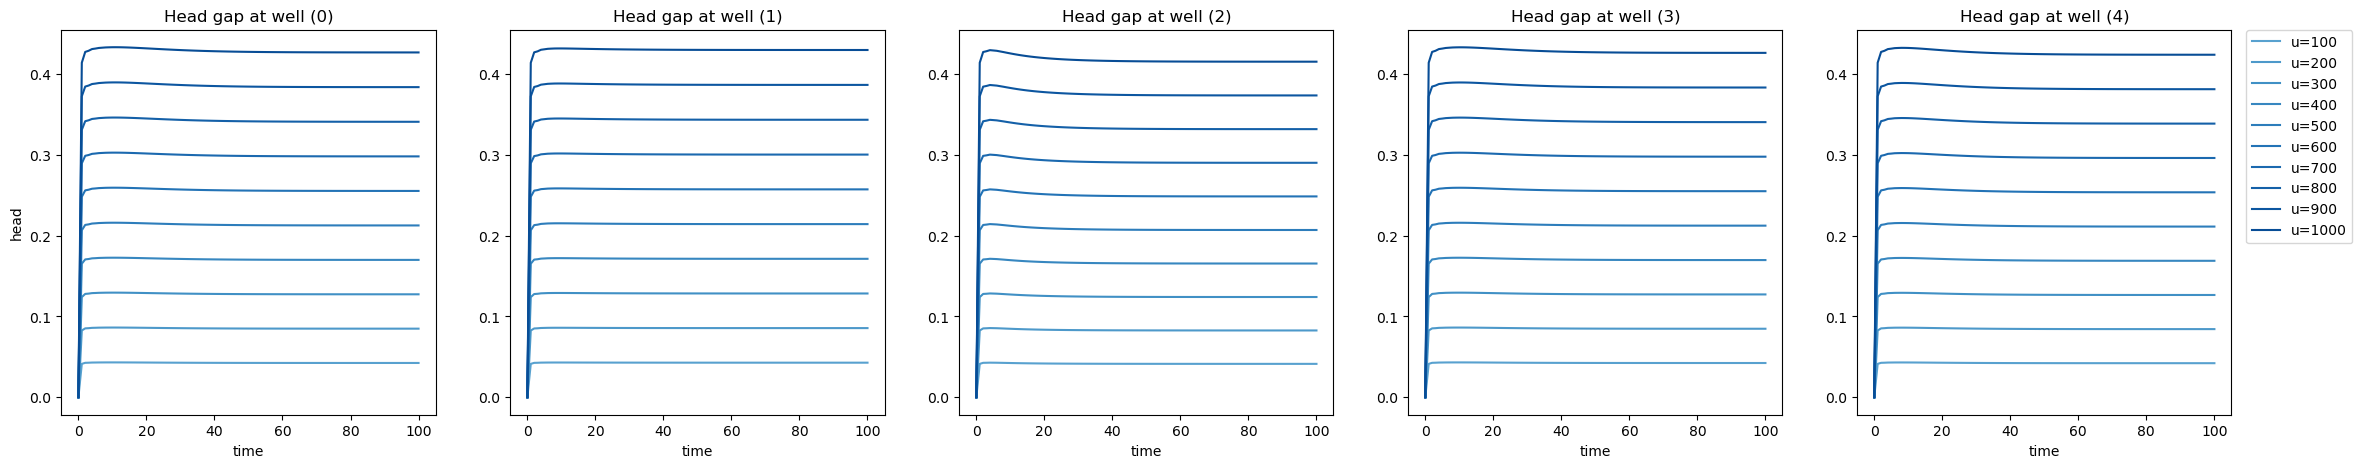

In [ ]:
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    for n_i in range(n_steps_intensity):
        # ax_h.plot(response[ii][n_i][well_pos[ii], :], "b-")
        # ax_h.plot(model_response[ii][n_i][well_pos[ii], :], "b--")
        ax_h.plot(model_head[ii, n_i, well_pos[ii], :] - head[ii, n_i, ii, :], color=plt.get_cmap('Blues')((15+n_i)/(n_steps_intensity+17)), label=f"u={int((n_i+1)*intensity_step)}")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Correction on the heads

## Using random inputs as training data

In [ ]:
n_sample = 100
train_command = [(np.random.randint(-30000,0, (1,5))*np.ones((T, 5))).T for _ in range(n_sample)]

In [ ]:
model.translate_state(system.get_state()[0,:,:]).flatten().shape

(100,)

In [ ]:
# Compute heads and costs for different commands at different wells
head_rd = np.array([np.hstack((system.get_heads_at_wells()[:,np.newaxis], np.zeros((n_well, T))))] * n_sample)
cost_rd = np.array([np.zeros((model.n_agent, T))] * n_sample)
for step in trange(n_sample):
    system.state = system.initial_state.copy()
    for k in range(T):
        system.apply_command(train_command[step][:,[k]])
        head_rd[step, :, k+1] = system.get_heads_at_wells()
        cost_rd[step, :, k] = system.compute_cost(train_command[step][:,[k]]).flatten()

100%|██████████| 100/100 [16:39<00:00, 10.00s/it]


In [ ]:
# Compute expected heads for those commands
B = sp.hstack(model.B_v)
system.state = system.initial_state.copy()
model_head_rd = np.array([np.hstack((model.translate_state(system.get_state()[0,:,:]), np.zeros((model.nx, T))))] * n_sample)
model_cost_rd = np.array([np.zeros((model.n_agent, T))] * n_sample)
for step in trange(n_sample):
    for k in range(T):
        input = np.kron(sp.vstack(model.well_to_command_v) @ train_command[step][:,[k]], np.array([[1] + [0]*(model.n_crops-1)]).T)
        model.state = model_head_rd[step, :, [k]].T
        model_head_rd[step, :, k+1] = (model.A @ model_head_rd[step, :, [k]].T + B @ input + model.C).flatten()

100%|██████████| 100/100 [00:02<00:00, 34.42it/s]


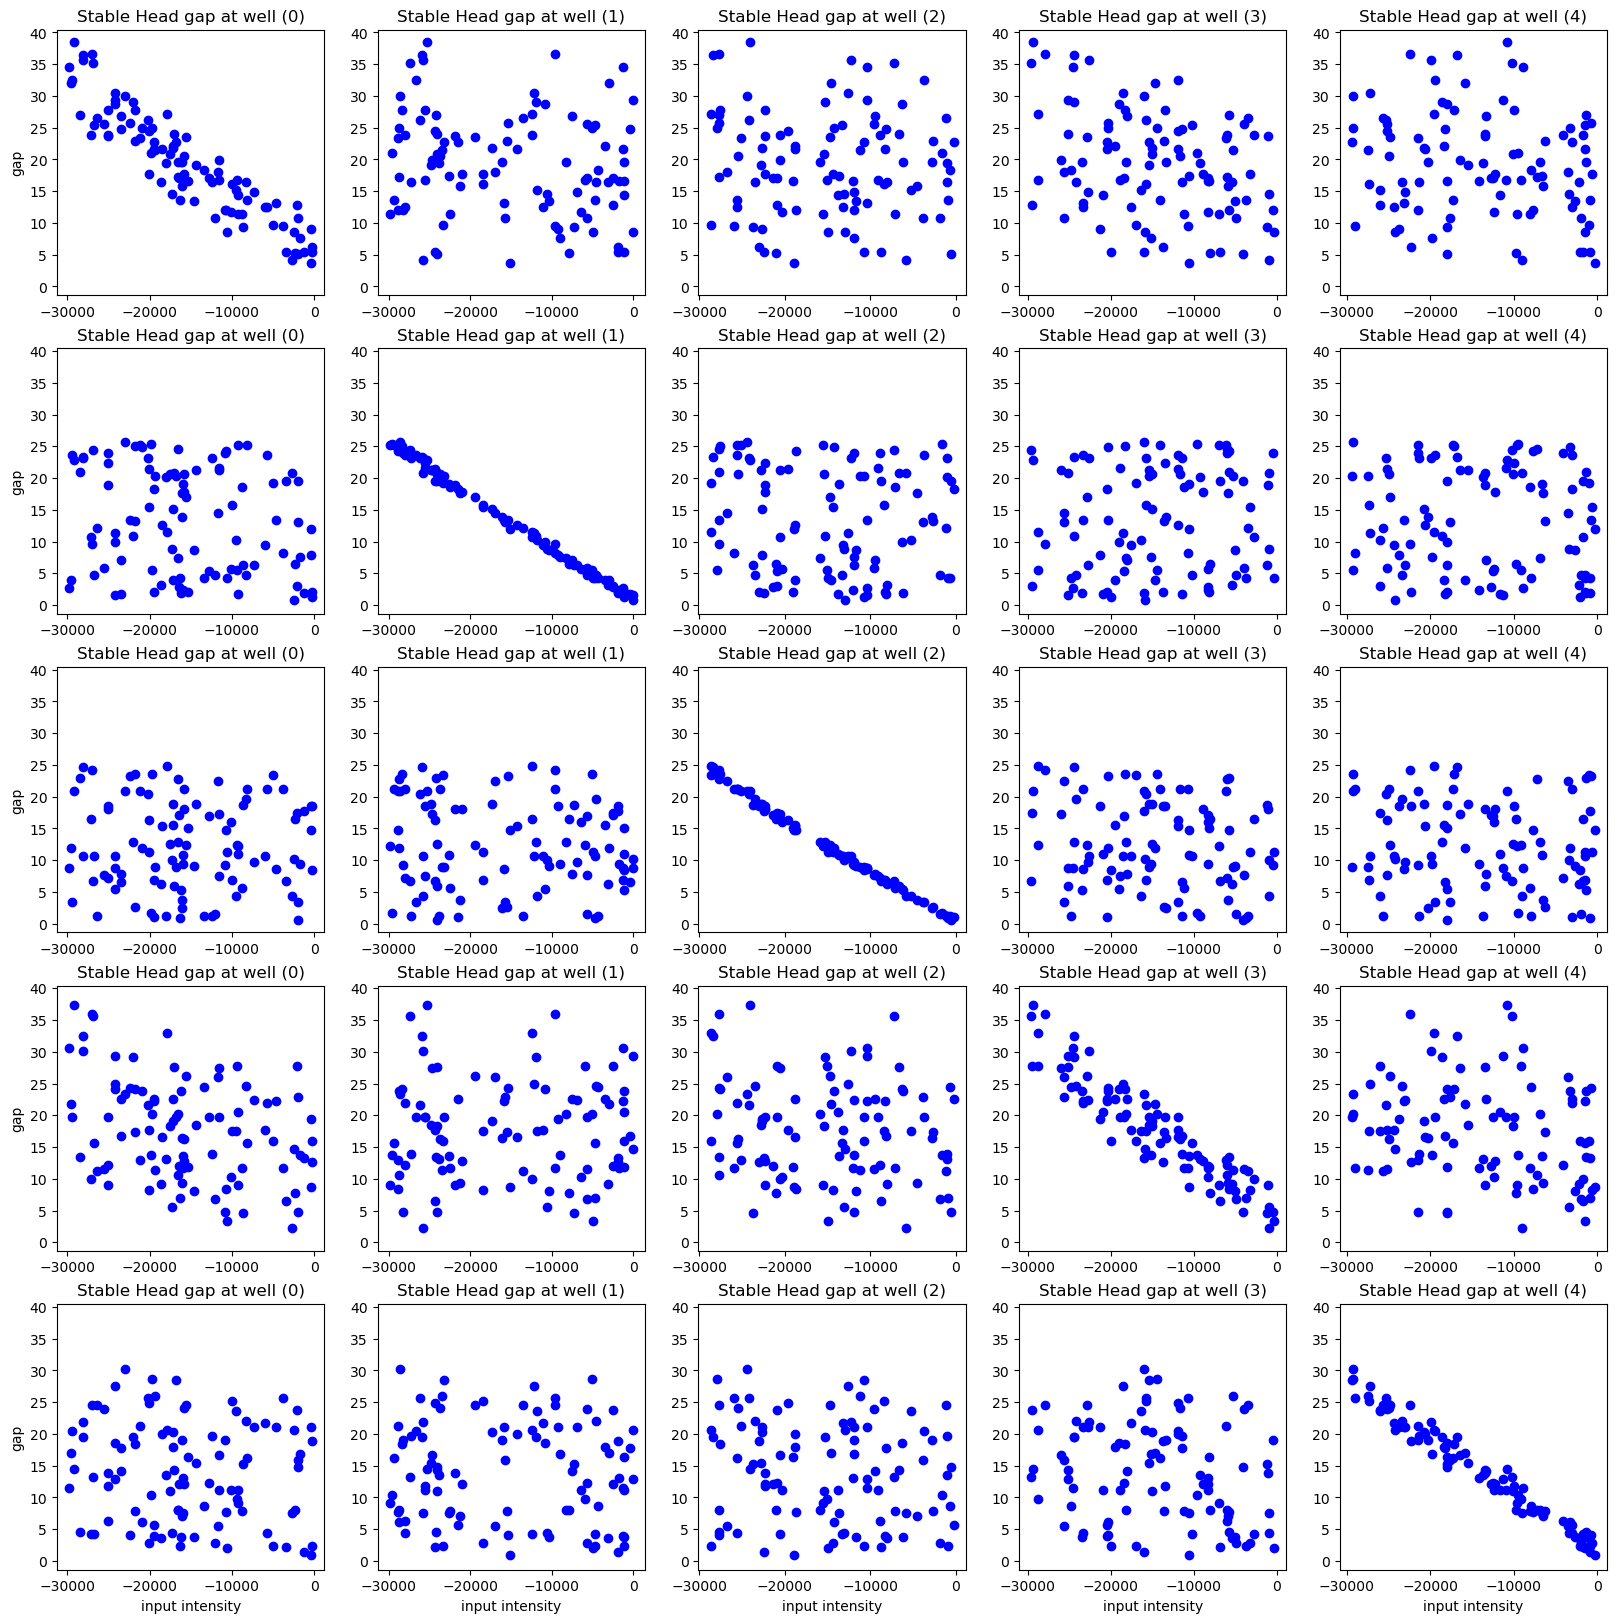

In [ ]:
fig_h = plt.figure(figsize=(20,20))
ax_h = None
for ii in range(n_well):
    for jj in range(n_well):
        ax_h = fig_h.add_subplot(5, 5, 5*jj+ii+1, sharey=ax_h)
        ttl = f"Stable Head gap at well ({ii})"
        ax_h.set_title(ttl)
        if jj == n_well-1:
            ax_h.set_xlabel("input intensity")
        if ii == 0:
            ax_h.set_ylabel("gap")
        ax_h.scatter([train_command[_][ii,0] for _ in range(n_sample)], model_head_rd[:, well_pos[jj], -1] - head_rd[:, jj, -1], color="blue", label="data")

The only real corelation seems to be in it's own well.

Fit linear function between pumping at well and error term in the same well.

In [ ]:
pumping_rates = np.array([[train_command[_][ii,0] for _ in range(n_sample)] for ii in range(n_well)])
error = np.array([model_head_rd[:, well_pos[ii], -1] - head_rd[:, ii, -1] for ii in range(n_well)])

In [ ]:
res = least_squares(lambda x : (x*pumping_rates.flatten() - error.flatten()), x0 = 0)
cx_u = res.x

In [ ]:
cx_u

array([-0.00099165])

In [ ]:
res = least_squares(lambda x : ((pumping_rates.T*x).T - error).flatten(), x0 = [0,0,0,0,0])
cx_u_w = res.x
cx_u_w

array([-0.00116839, -0.00086235, -0.00082622, -0.00114539, -0.00097151])

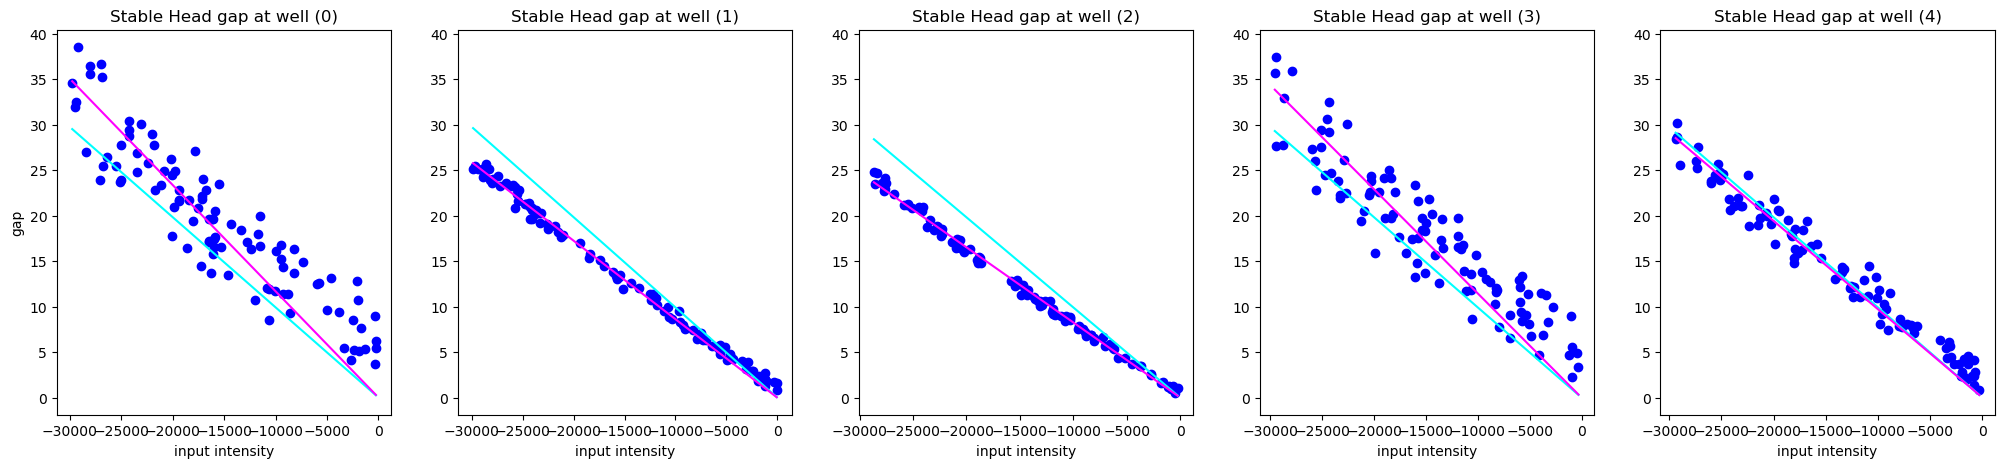

In [ ]:
fig_h = plt.figure(figsize=(25,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Stable Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("input intensity")
    if ii == 0:
        ax_h.set_ylabel("gap")
    ax_h.scatter([train_command[_][ii,0] for _ in range(n_sample)], model_head_rd[:, well_pos[ii], -1] - head_rd[:, ii, -1], color="blue", label="data")
    arg_sort = pumping_rates[ii,:].argsort()
    ax_h.plot(pumping_rates[ii,arg_sort], cx_u * pumping_rates[ii,arg_sort], color="cyan")
    ax_h.plot(pumping_rates[ii,arg_sort], (pumping_rates.T * cx_u_w).T[ii,arg_sort], color="magenta")

<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_5190/338150632.py:10: SyntaxWarning: invalid escape sequence '\D'
  ax_h.set_ylabel("$\Delta h$")


Text(20000, 25, '$\\widetilde{\\Delta h}(q) = \\alpha_h q$')

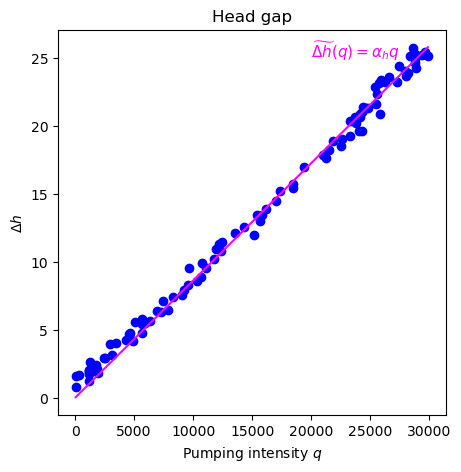

In [ ]:
fig_h = plt.figure(figsize=(5,5))
ax_h = None

ii=1
    
ax_h = fig_h.add_subplot(1, 1, 1, sharey=ax_h)
ttl = f"Head gap"
ax_h.set_title(ttl)
ax_h.set_xlabel("Pumping intensity $q$")
ax_h.set_ylabel("$\Delta h$")
ax_h.scatter([-train_command[_][ii,0] for _ in range(n_sample)], model_head_rd[:, well_pos[ii], -1] - head_rd[:, ii, -1], color="blue", label="data")
arg_sort = pumping_rates[ii,:].argsort()
ax_h.plot(-pumping_rates[ii,arg_sort], (pumping_rates.T * cx_u_w).T[ii,arg_sort], color="magenta")
ax_h.text(20000, 25, r"$\widetilde{\Delta h}(q) = \alpha_h q$", fontdict={'color':'magenta', 'fontsize':11})